## Notebook para análise exploratória 


In [ ]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("../data/pa3_dados")  
IMG = ROOT / "images"

classes = pd.read_csv(ROOT / "classes.csv")["label"].tolist()
print(len(classes), "classes")


21 classes


In [2]:
val  = pd.read_csv(ROOT / "labels/val.csv")
test = pd.read_csv(ROOT / "labels/test_public.csv")
r5   = pd.read_csv(ROOT / "labels/rotulos_5.csv")

contagem = pd.DataFrame({
    "rotulos_5": r5["label"].value_counts(),
    "val": val["label"].value_counts(),
    "test_public": test["label"].value_counts(),
}).fillna(0).astype(int).sort_values("test_public", ascending=False)
contagem


,rotulos_5,val,test_public
label,,,
american_black_bear,5,10,82
dog,5,10,67
american_crow,5,10,63
chicken,5,10,60
virginia_opossum,5,10,55
domestic_cat,5,10,48
red_fox,5,10,43
grey_fox,5,10,39
bobcat,5,10,34


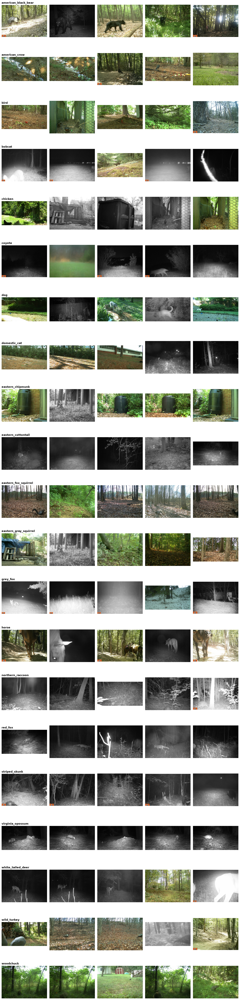

In [3]:
fig, axes = plt.subplots(21, 5, figsize=(15, 63))

for row, (classe, grupo) in enumerate(r5.groupby("label")):
    for col, image_id in enumerate(grupo["image_id"]):
        img = Image.open(IMG / "train" / f"{image_id}.jpg")
        ax = axes[row, col]
        ax.imshow(img)
        ax.axis("off")
        if col == 0:
            ax.set_title(classe, loc="left", fontsize=12, fontweight="bold")

plt.tight_layout()


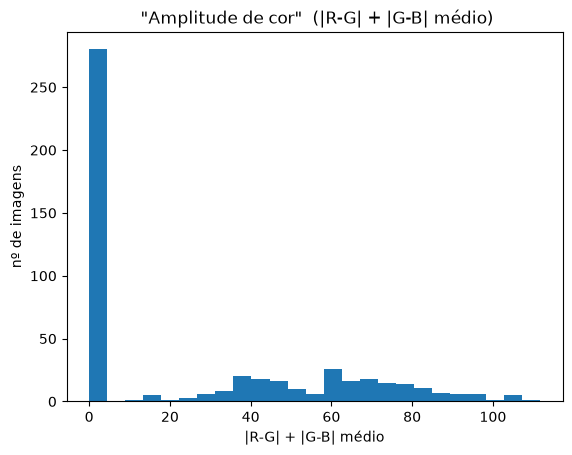

In [9]:
def colorido(path):
    """Média de |R-G| + |G-B|. Perto de 0 = foto IR (noturna)."""
    a = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    return float((np.abs(r - g) + np.abs(g - b)).mean())

rng = np.random.default_rng(0)
todas = sorted((IMG / "train").glob("*.jpg"))
amostra = rng.choice(todas, size=500, replace=False)

cor = np.array([colorido(p) for p in amostra])

plt.hist(cor, bins=25)
plt.xlabel("|R-G| + |G-B| médio")
plt.ylabel("nº de imagens")
plt.title(" \"Amplitude de cor\"  (|R-G| + |G-B| médio)");


Podemos ver que, considerando essa medida, muitas imagens ficam concentrada com média ~ 0, o que sugere que são as imagens de noite, confirmando:

noturnas: 56%


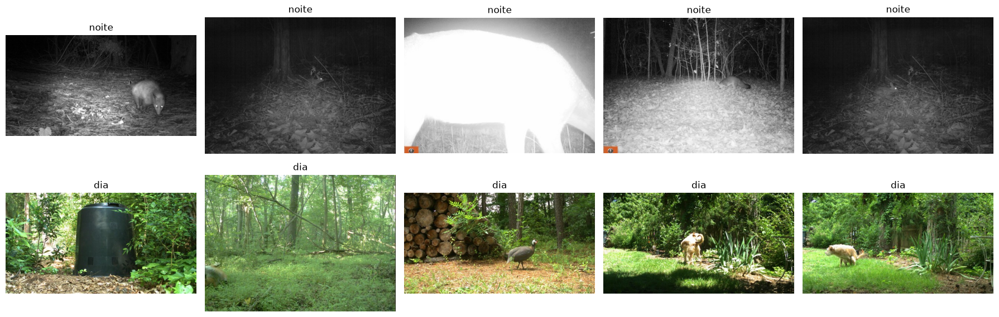

In [11]:
LIMIAR = 2.0
noite = cor < LIMIAR
print(f"noturnas: {noite.mean():.0%}")

fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, p in zip(axes[0], amostra[noite][:5]):
    ax.imshow(Image.open(p)); ax.set_title("noite"); ax.axis("off")
for ax, p in zip(axes[1], amostra[~noite][:5]):
    ax.imshow(Image.open(p)); ax.set_title("dia"); ax.axis("off")
plt.tight_layout()


O que confirma nossa hipótese.

[((512, 367), 3018), ((512, 270), 2457), ((512, 359), 817), ((512, 364), 204), ((512, 368), 9)]


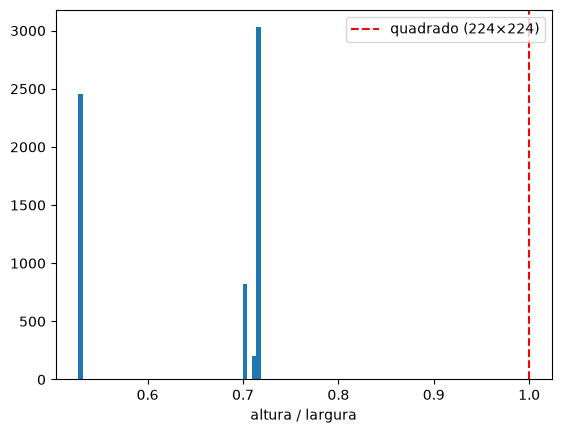

In [12]:
tamanhos = [Image.open(p).size for p in todas]   # (largura, altura)
print(Counter(tamanhos).most_common(10))

proporcao = np.array([h / w for w, h in tamanhos])
plt.hist(proporcao, bins=40)
plt.axvline(1.0, color="red", ls="--", label="quadrado (224×224)")
plt.xlabel("altura / largura")
plt.legend()
